<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/SLE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install packages
install.packages(c("ggplot2", "lmtest"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’




In [3]:
# Load libraries
library(ggplot2)
library(lmtest)

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




In [4]:
# Load dataset
df <- read.csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv")
head(df)

,rownames,id,read12,math12,female,asian,hispan,black,motheduc,fatheduc,lfaminc,hsgrad,cathhs,parcath
,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,124902,61.41,49.77,0,0,0,0,14,12,10.30895,1,0,1
2,2,124915,58.34,59.84,0,0,0,0,14,14,10.30895,1,0,1
3,3,124916,59.33,50.38,1,0,0,0,14,11,10.30895,1,0,1
4,4,124932,49.59,45.03,1,0,0,0,12,14,10.30895,1,0,1
5,5,124944,57.62,54.26,1,0,0,0,12,12,10.65726,1,0,1
6,6,124947,52.53,56.73,1,0,0,0,12,11,11.04292,1,0,1


In [5]:
# Structure and dimensions
str(df)
dim(df)

'data.frame':	7430 obs. of  14 variables:
 $ rownames: int  1 2 3 4 5 6 7 8 9 10 ...
 $ id      : int  124902 124915 124916 124932 124944 124947 124966 124968 124972 124974 ...
 $ read12  : num  61.4 58.3 59.3 49.6 57.6 ...
 $ math12  : num  49.8 59.8 50.4 45 54.3 ...
 $ female  : int  0 0 1 1 1 1 1 0 0 0 ...
 $ asian   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ hispan  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ black   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ motheduc: num  14 14 14 12 12 12 14 14 14 14 ...
 $ fatheduc: num  12 14 11 14 12 11 14 14 14 12 ...
 $ lfaminc : num  10.3 10.3 10.3 10.3 10.7 ...
 $ hsgrad  : int  1 1 1 1 1 1 1 1 1 1 ...
 $ cathhs  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ parcath : int  1 1 1 1 1 1 1 1 1 1 ...


[1] 7430   14

In [6]:
# Summary statistics
summary(df)

    rownames          id              read12          math12     
 Min.   :   1   Min.   : 124902   Min.   :29.15   Min.   :29.50  
 1st Qu.:1858   1st Qu.:2424049   1st Qu.:44.52   1st Qu.:45.02  
 Median :3716   Median :4592442   Median :53.08   Median :52.53  
 Mean   :3716   Mean   :4589838   Mean   :51.77   Mean   :52.13  
 3rd Qu.:5573   3rd Qu.:7241106   3rd Qu.:59.47   3rd Qu.:59.86  
 Max.   :7430   Max.   :7979086   Max.   :68.09   Max.   :71.37  
                                                                 
     female           asian             hispan           black        
 Min.   :0.0000   Min.   :0.00000   Min.   :0.0000   Min.   :0.00000  
 1st Qu.:0.0000   1st Qu.:0.00000   1st Qu.:0.0000   1st Qu.:0.00000  
 Median :1.0000   Median :0.00000   Median :0.0000   Median :0.00000  
 Mean   :0.5174   Mean   :0.05168   Mean   :0.1035   Mean   :0.07066  
 3rd Qu.:1.0000   3rd Qu.:0.00000   3rd Qu.:0.0000   3rd Qu.:0.00000  
 Max.   :1.0000   Max.   :1.00000   Max.   :1.

In [7]:
# Missing values
colSums(is.na(df))

rownames       id   read12   math12   female    asian   hispan    black 
       0        0        0        0        0        0        0        0 
motheduc fatheduc  lfaminc   hsgrad   cathhs  parcath 
       0        0        0     1460        0        0

In [8]:
# Select variables
data <- na.omit(df[, c("read12", "math12")])
head(data)

,read12,math12
,<dbl>,<dbl>
1,61.41,49.77
2,58.34,59.84
3,59.33,50.38
4,49.59,45.03
5,57.62,54.26
6,52.53,56.73


In [9]:
# Descriptive statistics
sapply(data, function(v) c(Mean = mean(v), SD = sd(v), Min = min(v), Max = max(v), Median = median(v)))

,read12,math12
Mean,51.772402,52.133623
SD,9.407761,9.459117
Min,29.150000,29.500000
Max,68.090000,71.370000
Median,53.080000,52.530000


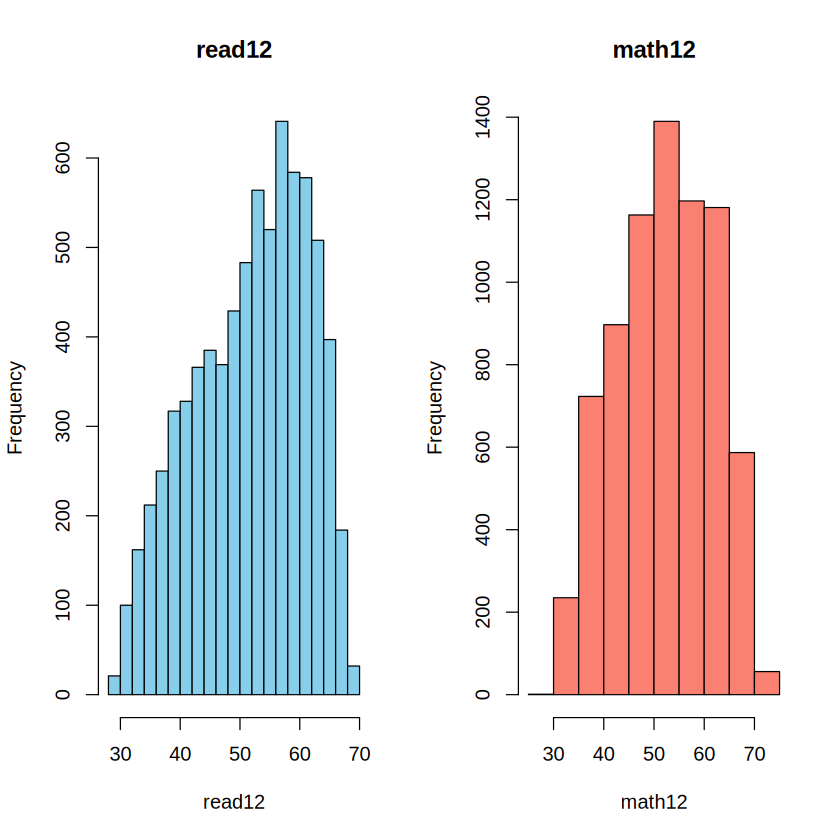

In [10]:
# Histograms
par(mfrow = c(1, 2))
hist(data$read12, col = "skyblue", main = "read12", xlab = "read12")
hist(data$math12, col = "salmon", main = "math12", xlab = "math12")
par(mfrow = c(1, 1))

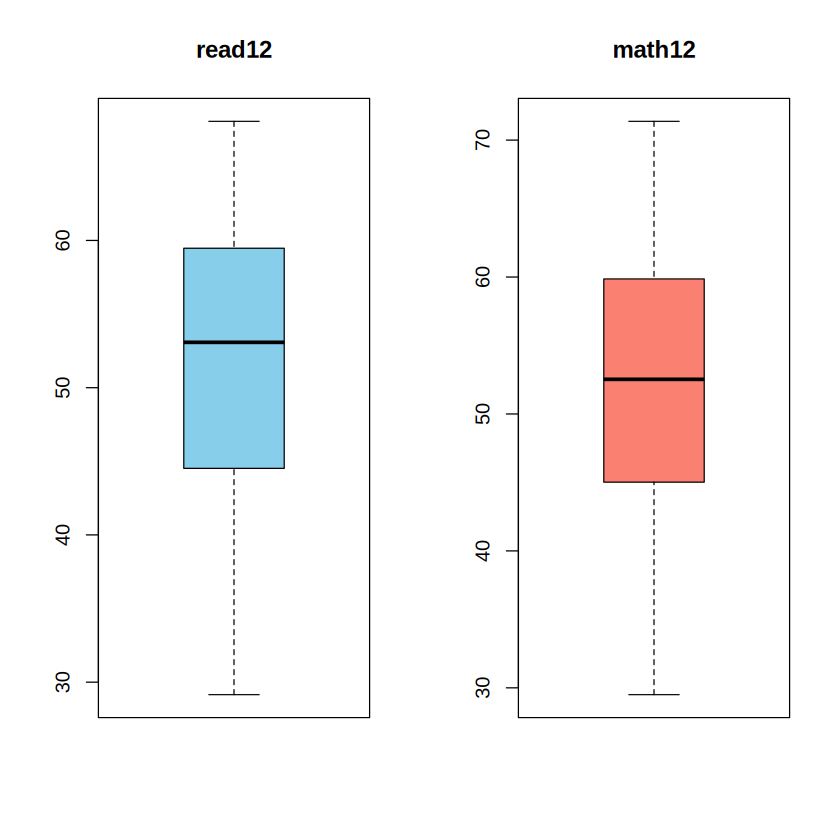

In [11]:
# Boxplots
par(mfrow = c(1, 2))
boxplot(data$read12, col = "skyblue", main = "read12")
boxplot(data$math12, col = "salmon", main = "math12")
par(mfrow = c(1, 1))

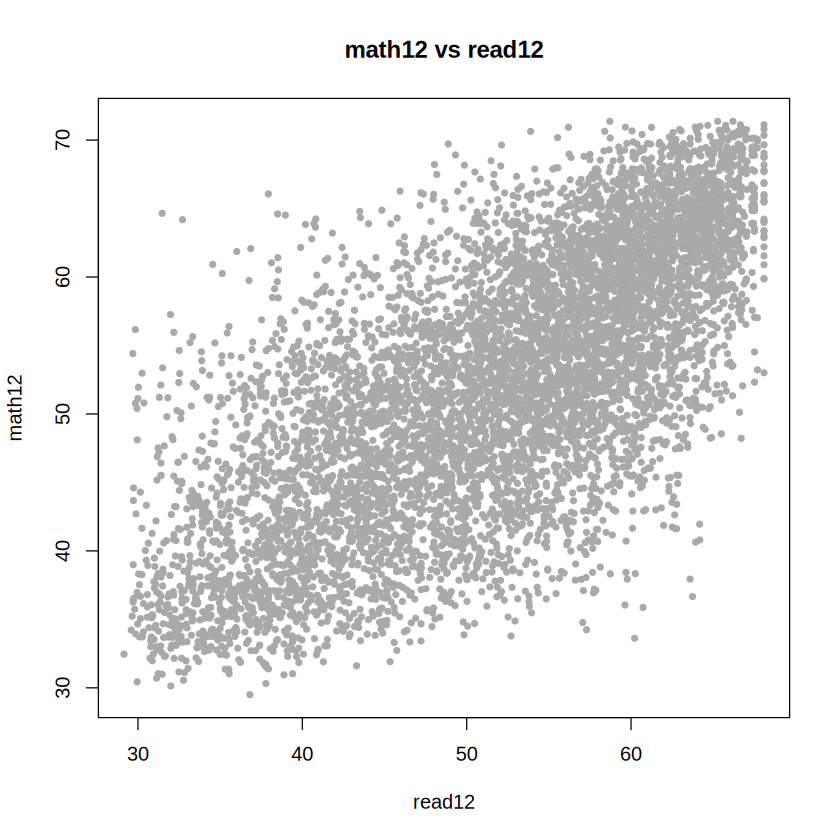

In [12]:
# Scatter plot
plot(data$read12, data$math12, pch = 20, col = "darkgray", xlab = "read12", ylab = "math12", main = "math12 vs read12")

In [13]:
# Correlation
cor(data$read12, data$math12)
cor.test(data$read12, data$math12)

[1] 0.7104134


	Pearson's product-moment correlation

data:  data$read12 and data$math12
t = 86.998, df = 7428, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.6989656 0.7214971
sample estimates:
      cor 
0.7104134 


In [14]:
# Train test split
set.seed(123)
idx <- sample(1:nrow(data), 0.8 * nrow(data))
train <- data[idx, ]
test <- data[-idx, ]
dim(train)
dim(test)

[1] 5944    2

[1] 1486    2

In [15]:
# Manual coefficient calculation
x <- train$read12
y <- train$math12
b1 <- sum((x - mean(x)) * (y - mean(y))) / sum((x - mean(x))^2)
b0 <- mean(y) - b1 * mean(x)
c(Intercept = b0, Slope = b1)

Intercept      Slope 
15.1241624  0.7146611

In [16]:
# Fit linear model
model <- lm(math12 ~ read12, data = train)
model


Call:
lm(formula = math12 ~ read12, data = train)

Coefficients:
(Intercept)       read12  
    15.1242       0.7147  


In [17]:
# Model summary
summary(model)


Call:
lm(formula = math12 ~ read12, data = train)

Residuals:
     Min       1Q   Median       3Q      Max 
-24.5411  -4.6045   0.1467   4.7615  27.0355 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 15.124162   0.480388   31.48   <2e-16 ***
read12       0.714661   0.009137   78.21   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.664 on 5942 degrees of freedom
Multiple R-squared:  0.5073,	Adjusted R-squared:  0.5072 
F-statistic:  6117 on 1 and 5942 DF,  p-value: < 2.2e-16


In [18]:
# Coefficients and confidence intervals
coef(model)
confint(model, level = 0.95)

(Intercept)      read12 
 15.1241624   0.7146611

,2.5 %,97.5 %
(Intercept),14.1824275,16.0658973
read12,0.6967489,0.7325734


In [19]:
# ANOVA table
anova(model)

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
read12,1,271700.7,271700.69419,6117.465,0
Residuals,5942,263907.6,44.41393,NA,NA


In [20]:
# R squared manual
SST <- sum((y - mean(y))^2)
SSE <- sum(residuals(model)^2)
SSR <- SST - SSE
c(SST = SST, SSR = SSR, SSE = SSE, R2 = SSR / SST, Adj_R2 = summary(model)$adj.r.squared)

SST          SSR          SSE           R2       Adj_R2 
5.356083e+05 2.717007e+05 2.639076e+05 5.072750e-01 5.071921e-01

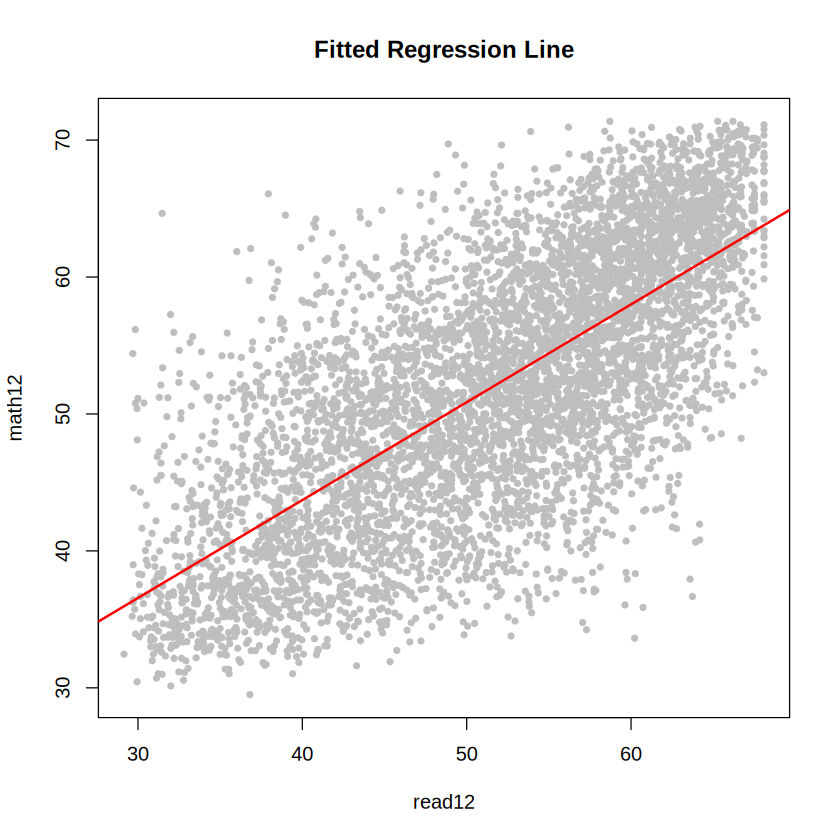

In [21]:
# Regression line base plot
plot(train$read12, train$math12, pch = 20, col = "gray", xlab = "read12", ylab = "math12", main = "Fitted Regression Line")
abline(model, col = "red", lwd = 2)

In [22]:
# Fitted values and residuals
train$fitted <- fitted(model)
train$resid <- residuals(model)
head(train)

,read12,math12,fitted,resid
,<dbl>,<dbl>,<dbl>,<dbl>
2463,52.39,57.26,52.56526,4.694740
2511,52.75,63.76,52.82254,10.937462
2227,63.08,64.35,60.20499,4.145013
526,56.18,61.40,55.27383,6.126174
4291,68.09,65.89,63.78544,2.104560
2986,45.57,44.00,47.69127,-3.691271


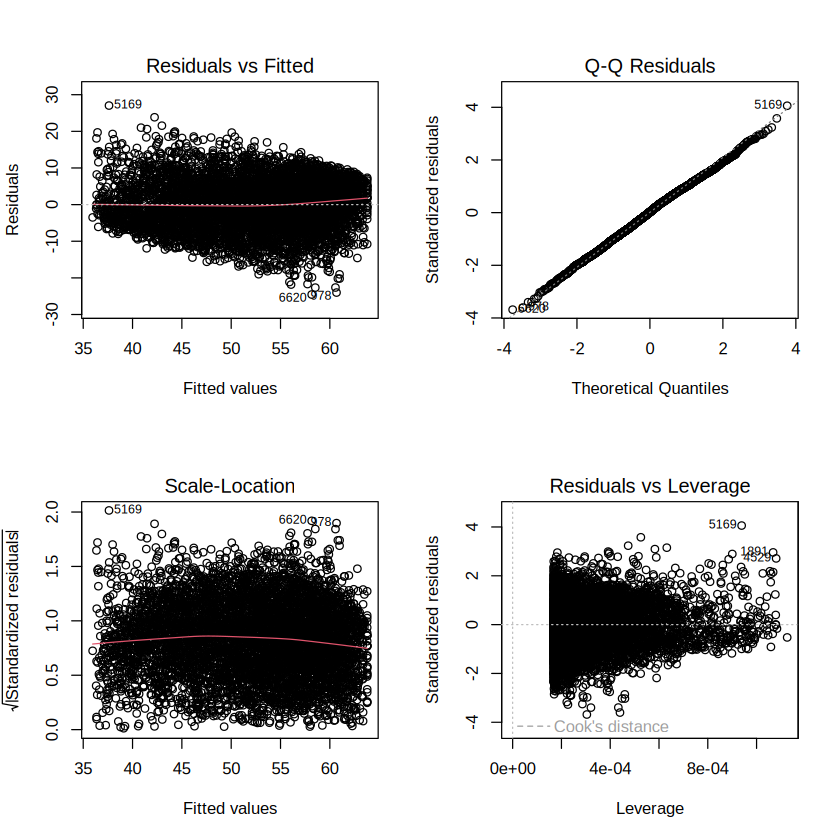

In [23]:
# Diagnostic plots
par(mfrow = c(2, 2))
plot(model)
par(mfrow = c(1, 1))

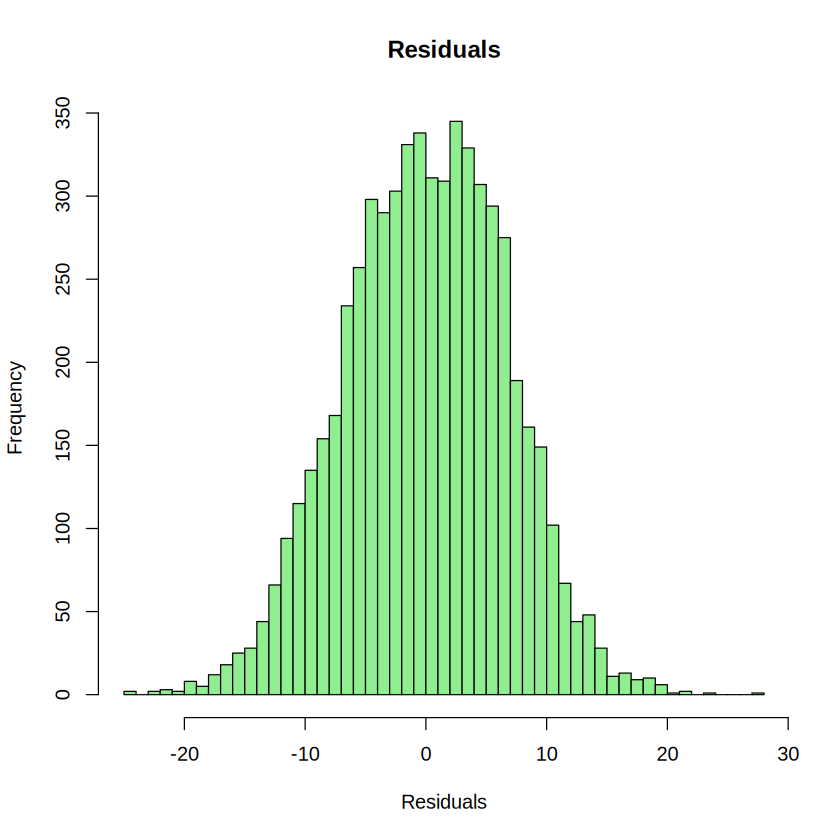

In [24]:
# Residual histogram
hist(train$resid, breaks = 40, col = "lightgreen", main = "Residuals", xlab = "Residuals")


	Shapiro-Wilk normality test

data:  sample(train$resid, min(5000, length(train$resid)))
W = 0.99847, p-value = 9.776e-05


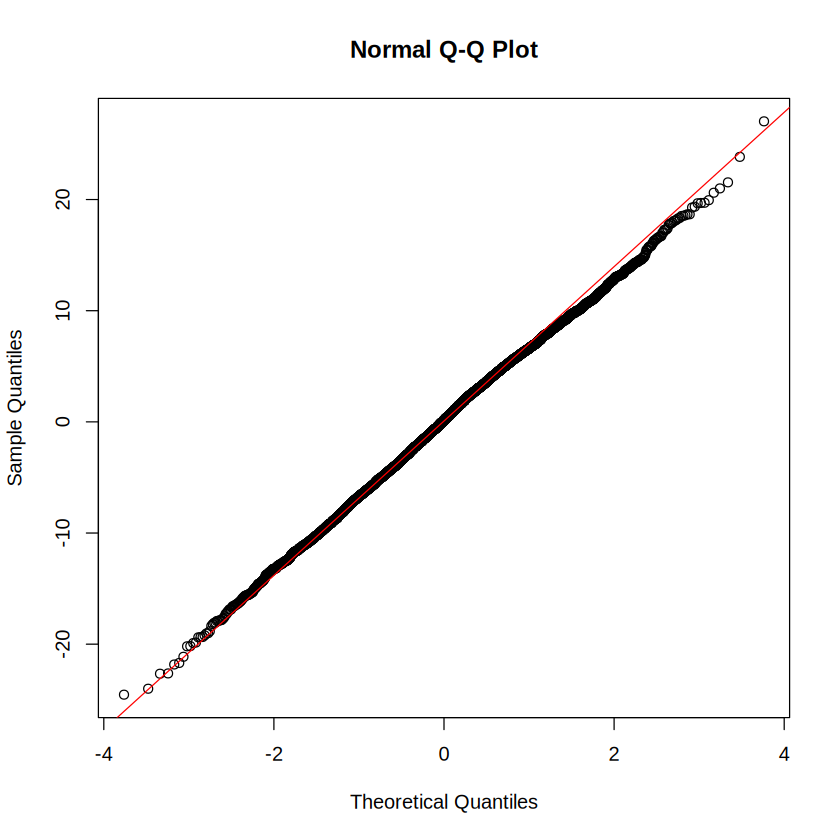

In [25]:
# Normality test
qqnorm(train$resid)
qqline(train$resid, col = "red")
shapiro.test(sample(train$resid, min(5000, length(train$resid))))

In [26]:
# Homoscedasticity test
bptest(model)


	studentized Breusch-Pagan test

data:  model
BP = 14.801, df = 1, p-value = 0.0001195


In [27]:
# Homoscedasticity test
bptest(model)


	studentized Breusch-Pagan test

data:  model
BP = 14.801, df = 1, p-value = 0.0001195


In [28]:
# Independence test
dwtest(model)


	Durbin-Watson test

data:  model
DW = 1.9813, p-value = 0.236
alternative hypothesis: true autocorrelation is greater than 0


[1] 181

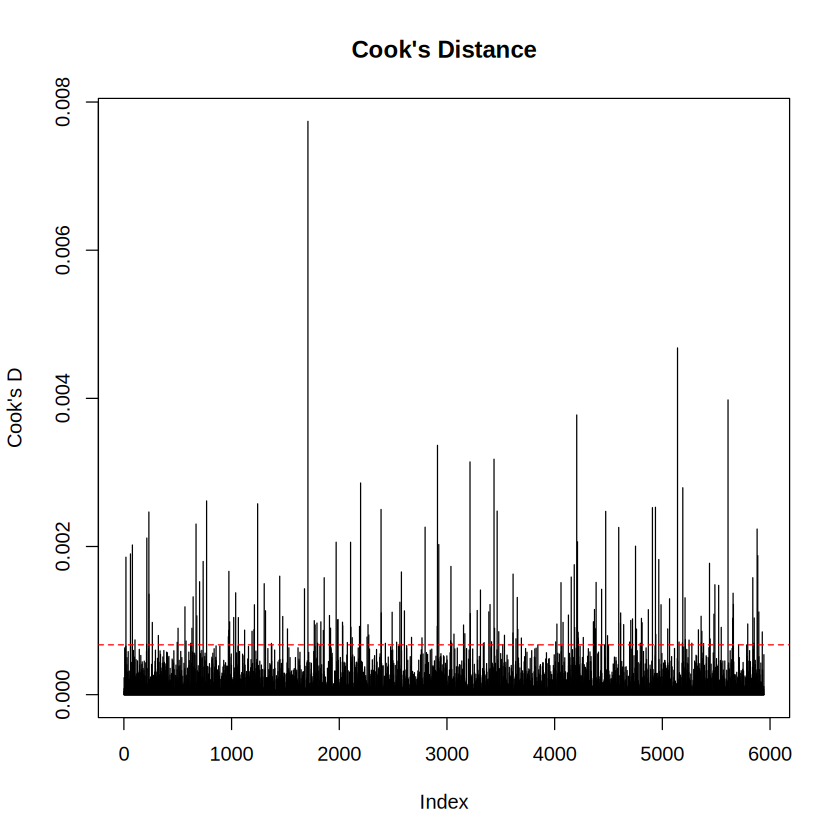

In [29]:
# Influential points
cooks <- cooks.distance(model)
plot(cooks, type = "h", main = "Cook's Distance", ylab = "Cook's D")
abline(h = 4 / nrow(train), col = "red", lty = 2)
sum(cooks > 4 / nrow(train))

In [30]:
# Predict on test set
test$pred <- predict(model, newdata = test)
head(test)

,read12,math12,pred
,<dbl>,<dbl>,<dbl>
4,49.59,45.03,50.56421
10,60.23,62.72,58.16820
11,53.03,46.86,53.02264
12,58.25,52.05,56.75317
14,38.51,61.41,42.64576
15,43.15,45.54,45.96179


In [31]:
# Evaluation metrics
rmse <- sqrt(mean((test$math12 - test$pred)^2))
mae <- mean(abs(test$math12 - test$pred))
r2 <- 1 - sum((test$math12 - test$pred)^2) / sum((test$math12 - mean(test$math12))^2)
c(RMSE = rmse, MAE = mae, R2_test = r2)

RMSE       MAE   R2_test 
6.6306182 5.3197739 0.4936581

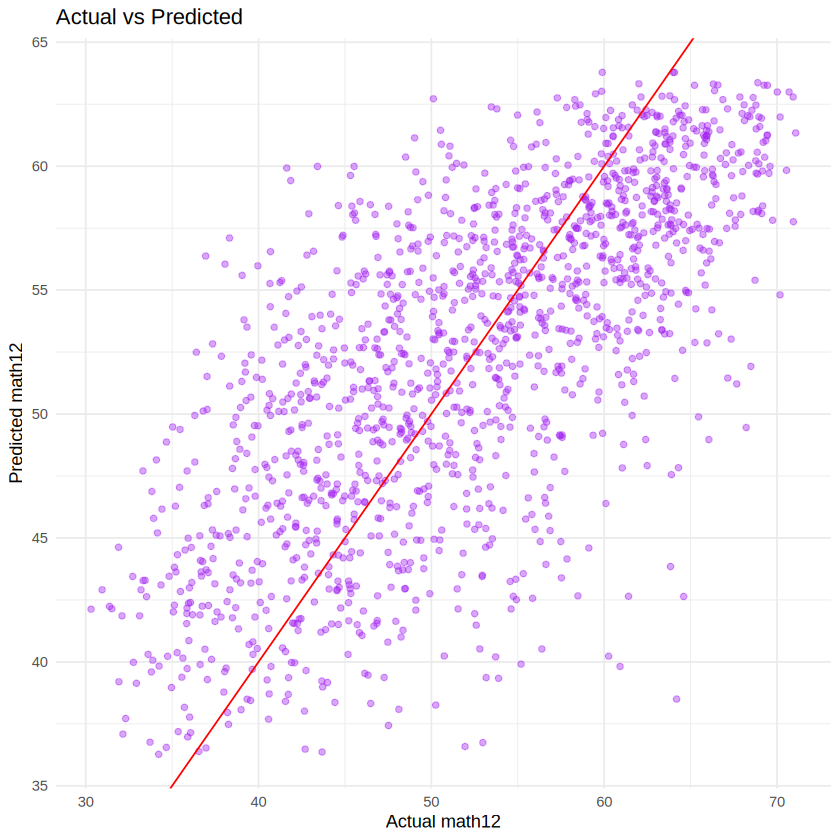

In [32]:
# Actual vs predicted
ggplot(test, aes(math12, pred)) +
  geom_point(alpha = 0.4, color = "purple") +
  geom_abline(slope = 1, intercept = 0, color = "red") +
  labs(title = "Actual vs Predicted", x = "Actual math12", y = "Predicted math12") +
  theme_minimal()

In [33]:
# Confidence and prediction intervals
new <- data.frame(read12 = c(40, 50, 60))
predict(model, new, interval = "confidence")
predict(model, new, interval = "prediction")

,fit,lwr,upr
1,43.71061,43.44086,43.98035
2,50.85722,50.68500,51.02944
3,58.00383,57.77860,58.22906


,fit,lwr,upr
1,43.71061,30.64322,56.77799
2,50.85722,37.79148,63.92296
3,58.00383,44.93729,71.07037


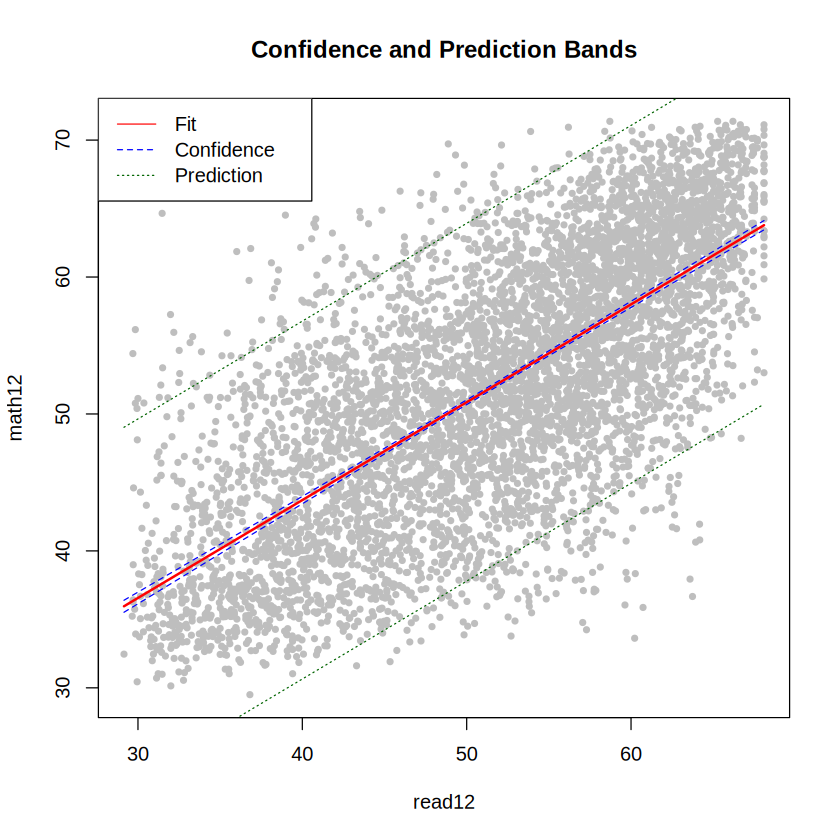

In [34]:
# Interval bands plot
grid <- data.frame(read12 = seq(min(data$read12), max(data$read12), length.out = 100))
ci <- predict(model, grid, interval = "confidence")
pi <- predict(model, grid, interval = "prediction")
plot(train$read12, train$math12, pch = 20, col = "gray", xlab = "read12", ylab = "math12", main = "Confidence and Prediction Bands")
lines(grid$read12, ci[, 1], col = "red", lwd = 2)
lines(grid$read12, ci[, 2], col = "blue", lty = 2)
lines(grid$read12, ci[, 3], col = "blue", lty = 2)
lines(grid$read12, pi[, 2], col = "darkgreen", lty = 3)
lines(grid$read12, pi[, 3], col = "darkgreen", lty = 3)
legend("topleft", c("Fit", "Confidence", "Prediction"), col = c("red", "blue", "darkgreen"), lty = c(1, 2, 3))

In [35]:
# Regression equation
cat("math12 =", round(coef(model)[1], 4), "+", round(coef(model)[2], 4), "* read12\n")

math12 = 15.1242 + 0.7147 * read12
